# LSTM: predicción horaria de demanda de bicicletas

## Objetivo
Predecir el número de alquileres de la siguiente hora usando las 24 horas previas. Es regresión sobre una serie temporal; la arquitectura recurrente será LSTM.

## Dataset y justificación
Se utiliza [Bike Sharing de UCI](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), con registros horarios de Capital Bikeshare en 2011–2012 y variables meteorológicas y de calendario. Su estacionalidad diaria/semanal y los picos de demanda permiten estudiar dependencias temporales y errores reales de pronóstico. Se cita a Hadi Fanaee-T (2013), DOI 10.24432/C5W894, licencia CC BY 4.0.

## Plan del experimento
Se revisarán fechas, horas ausentes y duplicados. Las particiones serán cronológicas (aproximadamente 70/15/15 % del calendario). Se construirán ventanas de 24 horas realmente consecutivas, sin inventar demandas para horas ausentes. El preprocesamiento se ajustará solo con entrenamiento.

Se compararán dos LSTM pequeñas (16 y 32 unidades) con referencias de persistencia, día anterior y semana anterior. Se seleccionará por MAE de validación y se evaluará en prueba una vez fijada la configuración. Se reportarán MAE, RMSE, R², curvas, pronósticos y análisis de errores. No corresponde matriz de confusión, pues no hay clases.

## Ejecución y alcance
Ejecutar todas las celdas en orden en Colab; CPU es suficiente y se requiere internet para descargar desde UCI. Los modelos y métricas se generan en `/content/resultados_rnn`, una carpeta temporal que no se incorpora al guardar el notebook. Se conservarán las salidas visibles. Este experimento histórico no demuestra desempeño en ciudades o periodos distintos.

TensorFlow: 2.21.0
Filas y columnas del CSV: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


Celdas faltantes en el CSV: 0
Timestamps duplicados: 0
Horas del calendario completo: 17544
Horas sin registro: 165
Periodo: 2011-01-01 00:00:00 a 2012-12-31 23:00:00


,Partición,Inicio,Fin,Horas calendario,Horas observadas
0,Entrenamiento,2011-01-01 00:00:00,2012-05-26 15:00:00,12280,12155
1,Validación,2012-05-26 16:00:00,2012-09-13 07:00:00,2632,2632
2,Prueba,2012-09-13 08:00:00,2012-12-31 23:00:00,2632,2592


,count,mean,std,min,25%,50%,75%,max
cnt,12155.0,159.832497,152.548718,1.00,34.0000,119.000,234.0000,957.0000
temp,12155.0,0.467908,0.188474,0.02,0.3200,0.460,0.6200,0.9600
hum,12155.0,0.627187,0.200341,0.00,0.4700,0.620,0.7900,1.0000
windspeed,12155.0,0.196155,0.125100,0.00,0.1045,0.194,0.2836,0.8507


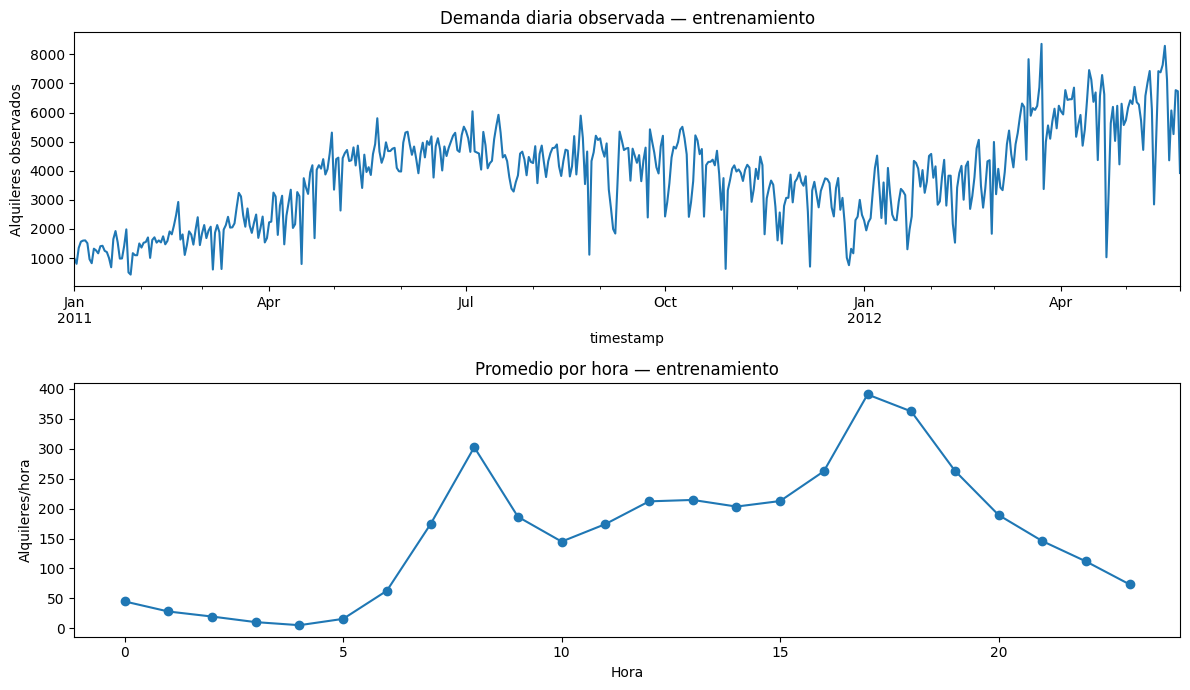

In [1]:
# 1. Herramientas, carga y auditoría temporal
import io
import json
import zipfile
import hashlib
from pathlib import Path
from urllib.request import urlopen
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import Markdown, display
import joblib

SEED = 42
keras.utils.set_random_seed(SEED)
OUT = Path('/content/resultados_rnn')
OUT.mkdir(parents=True, exist_ok=True)
URL = 'https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip'
with urlopen(URL, timeout=60) as response:
    raw_zip = response.read()
source_sha256 = hashlib.sha256(raw_zip).hexdigest()
with zipfile.ZipFile(io.BytesIO(raw_zip)) as archive:
    csv_names = [name for name in archive.namelist() if name.endswith('hour.csv')]
    assert len(csv_names) == 1, csv_names
    with archive.open(csv_names[0]) as csv_file:
        bike = pd.read_csv(csv_file)

print('TensorFlow:', tf.__version__)
print('Filas y columnas del CSV:', bike.shape)
display(bike.head())
print('Celdas faltantes en el CSV:', int(bike.isna().sum().sum()))
assert bike.isna().sum().sum() == 0
assert bike['hr'].between(0, 23).all()
assert (bike['cnt'] >= 0).all()
assert (bike['cnt'] == bike['casual'] + bike['registered']).all()
bike['timestamp'] = pd.to_datetime(bike['dteday']) + pd.to_timedelta(bike['hr'], unit='h')
print('Timestamps duplicados:', int(bike['timestamp'].duplicated().sum()))
assert not bike['timestamp'].duplicated().any()
bike = bike.sort_values('timestamp').set_index('timestamp')
grid = bike.reindex(pd.date_range(bike.index.min(), bike.index.max(), freq='h'))
grid.index.name = 'timestamp'
print('Horas del calendario completo:', len(grid))
print('Horas sin registro:', int(grid['cnt'].isna().sum()))
print('Periodo:', grid.index.min(), 'a', grid.index.max())

train_end = int(len(grid) * 0.70)
val_end = int(len(grid) * 0.85)
train_boundary = grid.index[train_end]
test_boundary = grid.index[val_end]
display(pd.DataFrame([
    {'Partición': name, 'Inicio': frame.index.min(), 'Fin': frame.index.max(),
     'Horas calendario': len(frame), 'Horas observadas': int(frame['cnt'].notna().sum())}
    for name, frame in [('Entrenamiento', grid.iloc[:train_end]),
                        ('Validación', grid.iloc[train_end:val_end]),
                        ('Prueba', grid.iloc[val_end:])]
]))

observed_train = grid.iloc[:train_end].dropna(subset=['cnt'])
display(observed_train[['cnt', 'temp', 'hum', 'windspeed']].describe().T)
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
observed_train['cnt'].resample('D').sum(min_count=1).plot(ax=axes[0])
axes[0].set(title='Demanda diaria observada — entrenamiento', ylabel='Alquileres observados')
observed_train.groupby(observed_train.index.hour)['cnt'].mean().plot(ax=axes[1], marker='o')
axes[1].set(title='Promedio por hora — entrenamiento', xlabel='Hora', ylabel='Alquileres/hora')
fig.tight_layout()
fig.savefig(OUT / 'exploracion_temporal.png', dpi=160)
plt.show()


## 2. Preprocesamiento y construcción de secuencias

Cada ejemplo usa las 24 horas anteriores al instante objetivo. Las entradas incluyen demanda observada, temperatura, humedad, viento, día laboral y representaciones cíclicas de hora y día de la semana. Todas las variables de entrada pertenecen al pasado; no se utiliza el clima observado de la hora que se intenta predecir.

Se excluyen `casual` y `registered`: su suma es `cnt` y utilizarlas en el instante objetivo revelaría la respuesta. Tampoco se utilizan ID ni fecha como número arbitrario.

Las horas ausentes se mantienen como faltantes en una cuadrícula horaria. Se descartan objetivos sin observación o sin 24 horas previas completas. Para comparar equitativamente con el pronóstico semanal, también se exige disponibilidad de la demanda de hace 168 horas; las cuatro alternativas se evalúan exactamente sobre los mismos objetivos. No se imputan respuestas y no se unen filas separadas por huecos como si fueran horas consecutivas.

Los escaladores de entradas y objetivo se ajustan únicamente con filas observadas de entrenamiento. Cada ventana se asigna según la fecha de su objetivo. Validación y prueba pueden usar contexto histórico anterior a su frontera: se simula pronóstico de una hora con actualización de observaciones, no un pronóstico recursivo de todo el periodo sin recibir datos nuevos.

Se verificará explícitamente que toda entrada sea anterior a su objetivo, que las particiones de objetivos no se solapen y que ninguna fecha futura intervenga en el ajuste del preprocesamiento.

In [2]:
# 2. Ventanas de 24 horas, sin fuga de información
WINDOW = 24
features = pd.DataFrame(index=grid.index)
for column in ['cnt', 'temp', 'hum', 'windspeed', 'workingday']:
    features[column] = grid[column]
features['hour_sin'] = np.sin(2*np.pi*grid.index.hour/24)
features['hour_cos'] = np.cos(2*np.pi*grid.index.hour/24)
features['weekday_sin'] = np.sin(2*np.pi*grid.index.dayofweek/7)
features['weekday_cos'] = np.cos(2*np.pi*grid.index.dayofweek/7)
feature_columns = features.columns.tolist()
assert 'casual' not in feature_columns and 'registered' not in feature_columns

input_scaler = StandardScaler()
target_scaler = StandardScaler()
fit_features = features.iloc[:train_end].dropna()
input_scaler.fit(fit_features)
target_scaler.fit(grid.iloc[:train_end][['cnt']].dropna())
assert fit_features.index.max() < train_boundary
scaled_features = input_scaler.transform(features).astype(np.float32)
observed_counts = grid['cnt'].to_numpy(dtype=float)

windows, targets, positions, previous_hour, previous_day, previous_week = [], [], [], [], [], []
for target_position in range(168, len(grid)):
    history_features = scaled_features[target_position-WINDOW:target_position]
    required_counts = observed_counts[[target_position, target_position-1,
                                      target_position-24, target_position-168]]
    if not np.isfinite(history_features).all() or not np.isfinite(required_counts).all():
        continue
    windows.append(history_features)
    targets.append(observed_counts[target_position])
    positions.append(target_position)
    previous_hour.append(observed_counts[target_position-1])
    previous_day.append(observed_counts[target_position-24])
    previous_week.append(observed_counts[target_position-168])

X_sequence = np.asarray(windows, dtype=np.float32)
y_sequence = np.asarray(targets, dtype=np.float32)
target_positions = np.asarray(positions, dtype=int)
target_times = grid.index[target_positions]
assert X_sequence.shape[1:] == (WINDOW, len(feature_columns))
assert np.isfinite(X_sequence).all() and np.isfinite(y_sequence).all()
assert target_times.is_unique and target_times.is_monotonic_increasing
assert np.all(grid.index[target_positions-1] < target_times)
assert np.all((target_times-grid.index[target_positions-WINDOW]) == pd.Timedelta(hours=WINDOW))

masks = {'train': target_positions < train_end,
         'validation': (target_positions >= train_end) & (target_positions < val_end),
         'test': target_positions >= val_end}
assert np.all(sum(mask.astype(int) for mask in masks.values()) == 1)
parts = {}
for name, mask in masks.items():
    assert mask.sum() > 0
    parts[name] = {'X': X_sequence[mask], 'y': y_sequence[mask],
                   'times': target_times[mask],
                   'y_scaled': target_scaler.transform(y_sequence[mask, None]).astype(np.float32)}
assert parts['train']['times'].max() < parts['validation']['times'].min()
assert parts['validation']['times'].max() < parts['test']['times'].min()

baseline_predictions = {'Persistencia (t-1)': np.asarray(previous_hour),
                        'Día anterior (t-24)': np.asarray(previous_day),
                        'Semana anterior (t-168)': np.asarray(previous_week)}
display(pd.DataFrame([
    {'Partición': name, 'Ventanas': len(part['y']), 'Inicio objetivo': part['times'].min(),
     'Fin objetivo': part['times'].max(), 'Forma de entrada': str(part['X'].shape)}
    for name, part in parts.items()
]))
print('Horas excluidas como objetivo:', len(grid)-len(target_positions))
print('Incluye el historial inicial, huecos y objetivos sin referencia semanal.')
print('VERIFICACIÓN TEMPORAL CORRECTA: entradas pasadas, objetivos separados y escalado con train.')


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,Partición,Ventanas,Inicio objetivo,Fin objetivo,Forma de entrada
0,train,10483,2011-01-08 04:00:00,2012-05-26 15:00:00,"(10483, 24, 9)"
1,validation,2632,2012-05-26 16:00:00,2012-09-13 07:00:00,"(2632, 24, 9)"
2,test,2435,2012-09-13 08:00:00,2012-12-31 23:00:00,"(2435, 24, 9)"


Horas excluidas como objetivo: 1994
Incluye el historial inicial, huecos y objetivos sin referencia semanal.
VERIFICACIÓN TEMPORAL CORRECTA: entradas pasadas, objetivos separados y escalado con train.


## 3. Arquitectura, referencias y selección

Se entrenan dos redes desde cero: LSTM de 16 o 32 unidades, seguida de dropout 0.2, Dense de 16 neuronas ReLU y una salida lineal. Cada entrada tiene forma (24 horas, 9 variables). La LSTM mantiene un estado interno para aprender dependencias dentro de la ventana; el estado se reinicia entre ejemplos (red no stateful).

Se utiliza Adam con learning rate 0.001, MSE sobre el objetivo estandarizado, batch size 64 y hasta 25 épocas. Early stopping con paciencia 5 y checkpoints restauran los pesos de menor pérdida de validación. No se mezclan aleatoriamente las ventanas durante el entrenamiento.

Las predicciones se convierten de nuevo a alquileres por hora y se limitan a cero como mínimo, una regla fijada antes de evaluar. No se redondean: se predice una cantidad esperada continua.

Referencias: repetir la hora anterior, la misma hora del día anterior y la misma hora de la semana anterior. Se seleccionará la LSTM por menor MAE de validación, usando RMSE para desempatar. También se identificará la mejor referencia usando solo validación. Las métricas finales se calcularán en las mismas fechas de prueba para todos los métodos. MAE y RMSE se expresan en alquileres/hora; RMSE penaliza más los errores grandes. R² se incluye como medida adicional.


EXPERIMENTO: LSTM 16


Model: "lstm_16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 16)             │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,953 (7.63 KB)

 Trainable params: 1,953 (7.63 KB)

 Non-trainable params: 0 (0.00 B)

... (5 outputs left out)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
164/164 - 5s - 28ms/step - loss: 0.5402 - mae_scaled: 0.5292 - val_loss: 0.8276 - val_mae_scaled: 0.6344
Epoch 2/25
164/164 - 2s - 14ms/step - loss: 0.3478 - mae_scaled: 0.4119 - val_loss: 0.5810 - val_mae_scaled: 0.5196
Epoch 3/25
164/164 - 3s - 20ms/step - loss: 0.2431 - mae_scaled: 0.3483 - val_loss: 0.4025 - val_mae_scaled: 0.4384
Epoch 4/25
164/164 - 3s - 19ms/step - loss: 0.1933 - mae_scaled: 0.3107 - val_loss: 0.2877 - val_mae_scaled: 0.3758
Epoch 5/25
164/164 - 4s - 24ms/step - loss: 0.1640 - mae_scaled: 0.2869 - val_loss: 0.2298 - val_mae_scaled: 0.3401
Epoch 6/25
164/164 - 2s - 13ms/step - loss: 0.1385 - mae_scaled: 0.2627 - val_loss: 0.1992 - val_mae_scaled: 0.3201
Epoch 7/25
164/164 - 3s - 17ms/step - loss: 0.1227 - mae_scaled: 0.2477 - val_loss: 0.1598 - val_mae_scaled: 0.2794
Epoch 8/25
164/164 - 2s - 10ms/step - loss: 0.1075 - mae_scaled: 0.2336 - val_loss: 0.1406 - val_mae_scaled: 0.2605
Epoch 9/25
164/164 - 2s - 11ms/step - loss: 0.0995 - mae_scaled: 0.2234 

,MAE,RMSE,R2,Mejor época,Épocas ejecutadas
Modelo,,,,,
Persistencia (t-1),92.0616,135.2529,0.6344,0,0
Día anterior (t-24),81.6440,136.9121,0.6253,0,0
Semana anterior (t-168),57.6539,97.8909,0.8085,0,0
LSTM 16,35.8094,52.1400,0.9457,22,25
LSTM 32,32.2758,47.1517,0.9556,25,25


LSTM FIJADA ANTES DE PRUEBA: LSTM 32
REFERENCIA FIJADA CON VALIDACIÓN: Semana anterior (t-168)


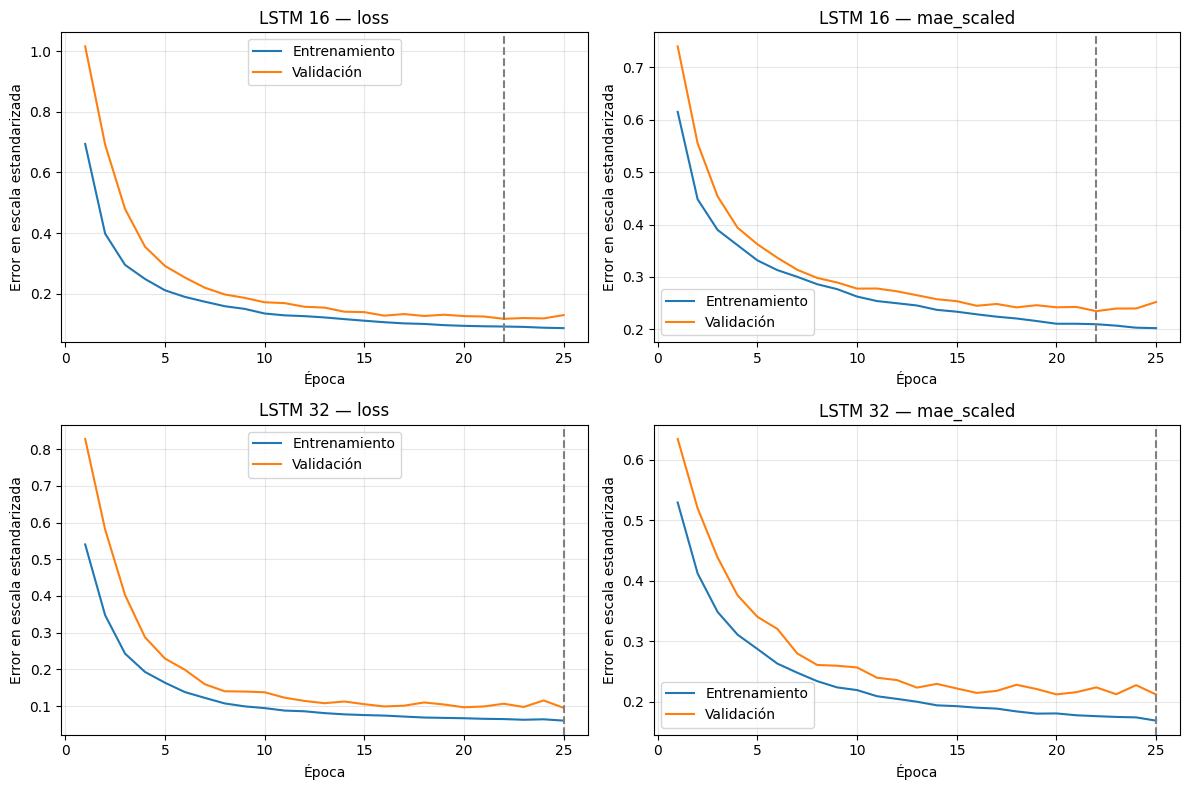

In [3]:
# 3. Entrenamiento y comparación exclusivamente en validación
MAX_EPOCHS = 25
BATCH_SIZE = 64

def regression_metrics(actual, predicted):
    return {'MAE': mean_absolute_error(actual, predicted),
            'RMSE': float(np.sqrt(mean_squared_error(actual, predicted))),
            'R2': r2_score(actual, predicted)}

def demand_predictions(model, x):
    scaled = model.predict(x, batch_size=256, verbose=0)
    return np.maximum(0, target_scaler.inverse_transform(scaled).ravel())

def build_lstm(units):
    model = keras.Sequential([
        keras.Input(shape=(WINDOW, len(feature_columns))),
        layers.LSTM(units),
        layers.Dropout(0.2, seed=SEED),
        layers.Dense(16, activation='relu'),
        layers.Dense(1)
    ], name=f'lstm_{units}')
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
                  loss='mse', metrics=[keras.metrics.MeanAbsoluteError(name='mae_scaled')])
    return model

val_rows = []
for name, predicted in baseline_predictions.items():
    val_rows.append({'Modelo': name, **regression_metrics(parts['validation']['y'], predicted[masks['validation']]),
                     'Mejor época': 0, 'Épocas ejecutadas': 0})
models_rnn, histories_rnn, val_predictions_rnn = {}, {}, {}
for units in [16, 32]:
    keras.utils.set_random_seed(SEED)
    model = build_lstm(units)
    name = f'LSTM {units}'
    print(chr(10) + 'EXPERIMENTO: ' + name)
    model.summary()
    smoke = model(parts['train']['X'][:2], training=False).numpy()
    assert smoke.shape == (2, 1) and np.isfinite(smoke).all()
    checkpoint = OUT / f'lstm_{units}.weights.h5'
    callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
                 keras.callbacks.ModelCheckpoint(str(checkpoint), monitor='val_loss',
                                                 save_best_only=True, save_weights_only=True),
                 keras.callbacks.TerminateOnNaN()]
    hist = model.fit(parts['train']['X'], parts['train']['y_scaled'],
                     validation_data=(parts['validation']['X'], parts['validation']['y_scaled']),
                     epochs=MAX_EPOCHS, batch_size=BATCH_SIZE, shuffle=False,
                     callbacks=callbacks, verbose=2)
    assert np.isfinite(hist.history['loss']).all()
    model.load_weights(str(checkpoint))
    predictions = demand_predictions(model, parts['validation']['X'])
    assert np.isfinite(predictions).all()
    models_rnn[name], histories_rnn[name], val_predictions_rnn[name] = model, hist.history, predictions
    val_rows.append({'Modelo': name, **regression_metrics(parts['validation']['y'], predictions),
                     'Mejor época': int(np.argmin(hist.history['val_loss']))+1,
                     'Épocas ejecutadas': len(hist.history['loss'])})
    pd.DataFrame(hist.history).to_csv(OUT / f'historial_lstm_{units}.csv', index=False)

validation_results_rnn = pd.DataFrame(val_rows).set_index('Modelo')
display(validation_results_rnn.round(4))
selected_name_rnn = validation_results_rnn.loc[list(models_rnn)].sort_values(['MAE', 'RMSE']).index[0]
selected_baseline_rnn = validation_results_rnn.loc[list(baseline_predictions)].sort_values(['MAE', 'RMSE']).index[0]
selected_rnn = models_rnn[selected_name_rnn]
print('LSTM FIJADA ANTES DE PRUEBA:', selected_name_rnn)
print('REFERENCIA FIJADA CON VALIDACIÓN:', selected_baseline_rnn)
validation_results_rnn.to_csv(OUT / 'comparacion_validacion.csv')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for row, (name, hist) in enumerate(histories_rnn.items()):
    for col, metric in enumerate(['loss', 'mae_scaled']):
        ax = axes[row, col]
        epochs = np.arange(1, len(hist[metric])+1)
        ax.plot(epochs, hist[metric], label='Entrenamiento')
        ax.plot(epochs, hist['val_'+metric], label='Validación')
        ax.axvline(int(np.argmin(hist['val_loss']))+1, color='gray', linestyle='--')
        ax.set(title=f'{name} — {metric}', xlabel='Época', ylabel='Error en escala estandarizada')
        ax.legend()
        ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / 'curvas_entrenamiento.png', dpi=160)
plt.show()


## 4. Evaluación final y análisis de errores

Una vez fijadas la LSTM y la referencia con validación, se calcularán las métricas de prueba en unidades originales. Se mostrarán una semana de pronósticos, observados frente a predichos, distribución de residuos y errores por hora. Los gráficos conservarán los huecos temporales como faltantes.

Se revisarán ejemplos de errores grandes sin modificar la configuración a partir de ellos. Los intervalos de confianza y la significancia estadística no se estimarán con muestras aleatorias independientes: las ventanas temporales se solapan y sus errores pueden estar correlacionados.

## 5. Guardado y reproducibilidad

Se guardan el modelo seleccionado, ambos escaladores, la configuración, las versiones, el hash del ZIP fuente, las fechas de los objetivos, métricas, predicciones e historiales en `/content/resultados_rnn`. Se recargan modelo y escaladores para comprobar el flujo completo de inferencia desde ventanas sin escalar. Los archivos son temporales de Colab; las salidas del notebook se conservan al guardarlo.

RESULTADOS FINALES EN PRUEBA — alquileres/hora


,MAE,RMSE,R2
Modelo,,,
Persistencia (t-1),82.1622,126.1476,0.6583
Día anterior (t-24),79.6041,131.9135,0.6264
Semana anterior (t-168),64.0263,107.7723,0.7506
LSTM 32,31.6875,47.9959,0.9505


,Real,LSTM,Referencia,Residuo,Error absoluto
timestamp,,,,,
2012-10-02 08:00:00,134.0,546.630005,805.0,412.630005,412.630005
2012-11-21 17:00:00,374.0,708.109985,583.0,334.109985,334.109985
2012-10-11 19:00:00,743.0,436.290009,534.0,-306.709991,306.709991
2012-10-19 17:00:00,425.0,720.450012,837.0,295.450012,295.450012
2012-12-31 17:00:00,164.0,415.000000,26.0,251.000000,251.000000
2012-09-18 18:00:00,281.0,508.059998,877.0,227.059998,227.059998
2012-11-23 16:00:00,357.0,572.880005,383.0,215.880005,215.880005
2012-09-20 17:00:00,976.0,764.359985,884.0,-211.639999,211.639999
2012-10-19 07:00:00,154.0,363.809998,392.0,209.809998,209.809998


,MAE,Sesgo,Casos
timestamp,,,
0,20.440001,3.130000,102
1,13.380000,2.810000,100
2,8.710000,2.580000,100
3,11.590000,11.060000,96
4,14.240000,14.240000,99
5,11.100000,1.700000,100
6,17.570000,-5.370000,100
7,42.180000,-15.860000,100
8,67.620003,-32.139999,101


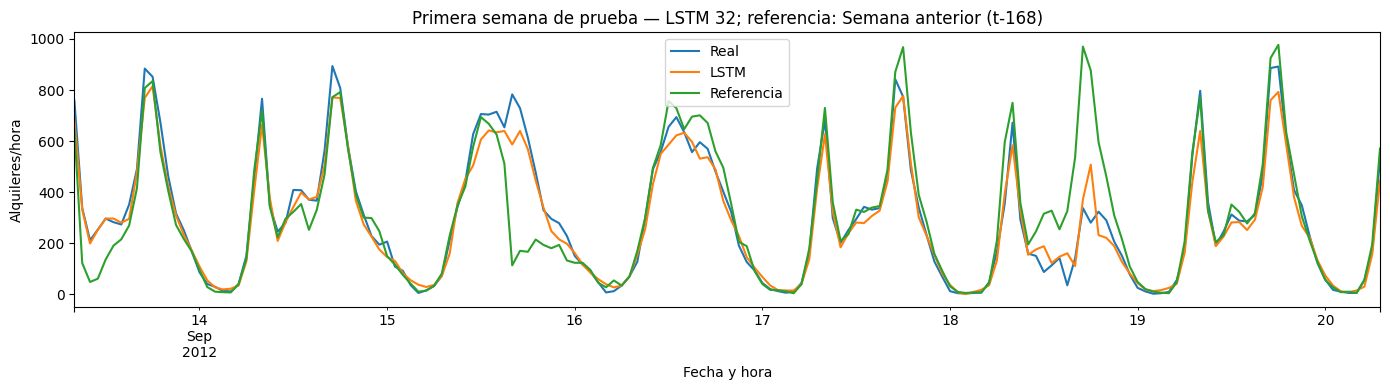

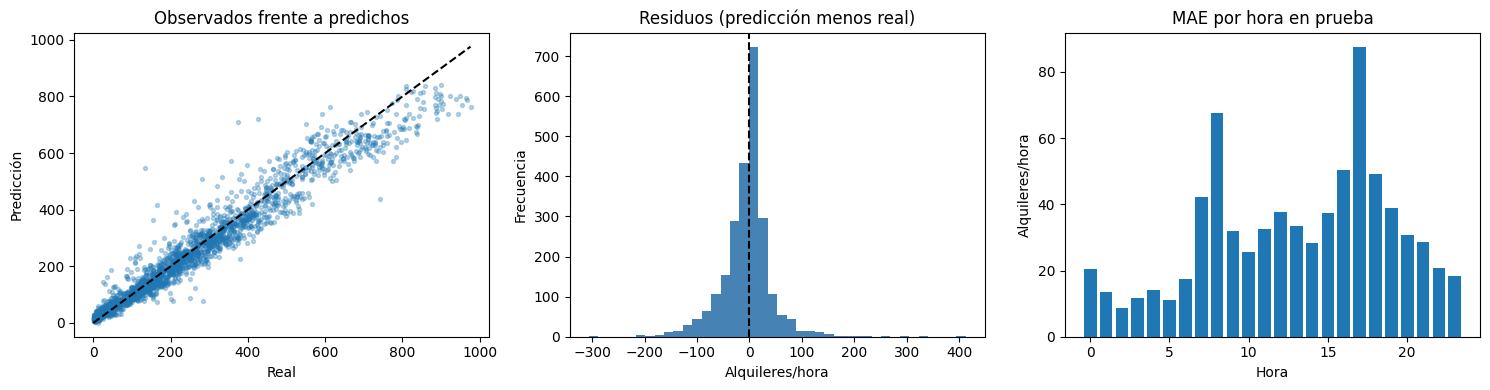

VERIFICACIÓN DE RECARGA CORRECTA: modelo y ambos escaladores reproducen la inferencia.


In [4]:
# 4. Evaluación en prueba: sin nueva selección de configuraciones
part_test = parts['test']
test_predictions_rnn = demand_predictions(selected_rnn, part_test['X'])
assert np.isfinite(test_predictions_rnn).all() and (test_predictions_rnn >= 0).all()
rows = []
for name, predictions in baseline_predictions.items():
    rows.append({'Modelo': name, **regression_metrics(part_test['y'], predictions[masks['test']])})
rows.append({'Modelo': selected_name_rnn, **regression_metrics(part_test['y'], test_predictions_rnn)})
test_results_rnn = pd.DataFrame(rows).set_index('Modelo')
print('RESULTADOS FINALES EN PRUEBA — alquileres/hora')
display(test_results_rnn.round(4))

prediction_frame = pd.DataFrame({'Real': part_test['y'], 'LSTM': test_predictions_rnn}, index=part_test['times'])
prediction_frame.index.name = 'timestamp'
prediction_frame['Referencia'] = baseline_predictions[selected_baseline_rnn][masks['test']]
prediction_frame['Residuo'] = prediction_frame['LSTM'] - prediction_frame['Real']
prediction_frame['Error absoluto'] = prediction_frame['Residuo'].abs()
display(prediction_frame.nlargest(10, 'Error absoluto').round(2))
error_by_hour = prediction_frame.groupby(prediction_frame.index.hour).agg(
    MAE=('Error absoluto','mean'), Sesgo=('Residuo','mean'), Casos=('Real','size'))
display(error_by_hour.round(2))

# Reindexar para que el gráfico no conecte artificialmente horas sin objetivo.
plot_frame = prediction_frame.reindex(pd.date_range(part_test['times'].min(), part_test['times'].max(), freq='h'))
first_week = plot_frame.loc[:plot_frame.index.min()+pd.Timedelta(hours=167)]
fig, ax = plt.subplots(figsize=(14, 4))
first_week[['Real','LSTM','Referencia']].plot(ax=ax)
ax.set(title=f'Primera semana de prueba — {selected_name_rnn}; referencia: {selected_baseline_rnn}',
       xlabel='Fecha y hora', ylabel='Alquileres/hora')
fig.tight_layout()
fig.savefig(OUT / 'pronostico_primera_semana.png', dpi=160)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(part_test['y'], test_predictions_rnn, s=8, alpha=0.3)
upper = max(float(part_test['y'].max()), float(test_predictions_rnn.max()))
axes[0].plot([0, upper], [0, upper], '--', color='black')
axes[0].set(title='Observados frente a predichos', xlabel='Real', ylabel='Predicción')
axes[1].hist(prediction_frame['Residuo'], bins=40, color='steelblue')
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(title='Residuos (predicción menos real)', xlabel='Alquileres/hora', ylabel='Frecuencia')
axes[2].bar(error_by_hour.index, error_by_hour['MAE'])
axes[2].set(title='MAE por hora en prueba', xlabel='Hora', ylabel='Alquileres/hora')
fig.tight_layout()
fig.savefig(OUT / 'analisis_errores.png', dpi=160)
plt.show()

# 5. Guardar modelo, escaladores y configuración.
selected_rnn.save(OUT / 'lstm_bicicletas.keras')
joblib.dump(input_scaler, OUT / 'escalador_entradas.joblib')
joblib.dump(target_scaler, OUT / 'escalador_objetivo.joblib')
loaded_rnn = keras.models.load_model(OUT / 'lstm_bicicletas.keras', compile=False)
loaded_input_scaler = joblib.load(OUT / 'escalador_entradas.joblib')
loaded_target_scaler = joblib.load(OUT / 'escalador_objetivo.joblib')
# Reconstruir 12 ventanas de validación desde variables originales.
validation_positions = target_positions[masks['validation']][:12]
loaded_windows = np.asarray([
    loaded_input_scaler.transform(features.iloc[pos-WINDOW:pos]).astype(np.float32)
    for pos in validation_positions
])
reloaded_predictions = np.maximum(0, loaded_target_scaler.inverse_transform(
    loaded_rnn.predict(loaded_windows, verbose=0)).ravel())
original_predictions = demand_predictions(selected_rnn, parts['validation']['X'][:12])
np.testing.assert_allclose(original_predictions, reloaded_predictions, rtol=1e-5, atol=1e-3)

from importlib.metadata import version
packages = ['tensorflow','keras','numpy','pandas','matplotlib','scikit-learn','joblib','h5py']
versions = {name: version(name) for name in packages}
config = {'dataset_url': URL, 'source_zip_sha256': source_sha256,
          'seed': SEED, 'window_hours': WINDOW, 'frequency': 'h',
          'feature_columns': feature_columns, 'target': 'cnt',
          'train_boundary_exclusive': str(train_boundary),
          'test_boundary_inclusive': str(test_boundary),
          'forecast': 'one-step rolling with previously observed demand',
          'missing_hours': 'drop windows with incomplete history; no target imputation',
          'evaluation_eligibility': '24 consecutive past hours plus observed lag168 and target',
          'postprocessing': 'inverse target scaler, then clip at zero',
          'selected_model': selected_name_rnn, 'selected_baseline': selected_baseline_rnn,
          'criterion': 'MAE validation; RMSE tie-break',
          'max_epochs': MAX_EPOCHS, 'batch_size': BATCH_SIZE, 'versions': versions}
(OUT / 'configuracion.json').write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding='utf-8')
(OUT / 'requirements.txt').write_text(chr(10).join(f'{name}=={v}' for name,v in versions.items())+chr(10), encoding='utf-8')
test_results_rnn.to_csv(OUT / 'metricas_prueba.csv')
prediction_frame.to_csv(OUT / 'predicciones_prueba.csv')
error_by_hour.to_csv(OUT / 'errores_por_hora.csv')
pd.DataFrame({'timestamp': target_times,
              'particion': np.select([masks['train'], masks['validation']], ['train','validation'], default='test'),
              'posicion_objetivo': target_positions}).to_csv(OUT / 'particiones.csv', index=False)
print('VERIFICACIÓN DE RECARGA CORRECTA: modelo y ambos escaladores reproducen la inferencia.')


## 6. Conclusiones, limitaciones y mejoras

La siguiente celda redacta el resumen con resultados calculados, sin cifras copiadas manualmente. Las conclusiones se limitan a las fechas elegibles de esta evaluación, no a todas las horas del calendario. Exigir historia completa y referencia semanal excluye horas y puede sesgar la evaluación hacia periodos con mejor cobertura.

Las ventanas se solapan, los errores pueden estar autocorrelacionados y las particiones abarcan estaciones diferentes. Una sola partición y semilla no prueban estabilidad ni significancia estadística. La LSTM usa demanda y clima ya observados: sus resultados corresponden a pronóstico de una hora con actualización del historial, no a predecir meses sin recibir nuevas observaciones.

El clima de la siguiente hora no se utiliza; incorporar pronósticos meteorológicos reales sería un experimento distinto. También podrían estudiarse validación de origen móvil, más historia, variables de calendario del objetivo y datos recientes. Las mejoras se seleccionarían con validación y se evaluarían en nuevos periodos independientes. No se reajusta el modelo a partir de los errores de prueba mostrados aquí.

In [5]:
# 6. Resumen calculado desde las métricas reales
lstm_scores = test_results_rnn.loc[selected_name_rnn]
reference_scores = test_results_rnn.loc[selected_baseline_rnn]
relative_improvement = 100*(reference_scores['MAE']-lstm_scores['MAE'])/reference_scores['MAE']
comparison_text = ('redujo' if relative_improvement >= 0 else 'aumentó')
hist_selected = histories_rnn[selected_name_rnn]
best_epoch_rnn = int(np.argmin(hist_selected['val_loss']))+1
budget_note = ('La mejor época coincide con el límite fijado; no se demuestra convergencia completa.'
               if best_epoch_rnn == MAX_EPOCHS else
               'Se recuperaron los pesos de menor pérdida de validación, no necesariamente los de la última época.')
worst_hour = int(error_by_hour['MAE'].idxmax())
summary_rnn = f'''### Resultados y aprendizajes

- El archivo horario contiene **{len(bike):,} registros** y el calendario completo tiene **{len(grid):,} horas**, de las cuales **{int(grid['cnt'].isna().sum())}** no tienen registro. No se encontraron timestamps duplicados. El conteo efectivo del CSV se utiliza en lugar de asumir el conteo resumido del catálogo.
- Se construyeron **{len(target_positions):,} ventanas válidas** de 24 horas y 9 variables: **{len(parts['train']['y']):,}** de entrenamiento, **{len(parts['validation']['y']):,}** de validación y **{len(parts['test']['y']):,}** de prueba. Se verificaron orden temporal, ausencia de solapamiento entre objetivos y ajuste de escaladores solo con entrenamiento.
- La configuración seleccionada por MAE de validación fue **{selected_name_rnn}**, con **{selected_rnn.count_params():,} parámetros**. Se conservó la época **{best_epoch_rnn}** de **{len(hist_selected['loss'])}** ejecutadas. {budget_note}
- En prueba obtuvo **MAE {lstm_scores['MAE']:.2f} alquileres/hora**, **RMSE {lstm_scores['RMSE']:.2f} alquileres/hora** y **R² {lstm_scores['R2']:.4f}**. MAE representa el error absoluto promedio sobre los objetivos elegibles; no significa que cada predicción tenga ese error.
- La referencia seleccionada previamente fue **{selected_baseline_rnn}**, con MAE de prueba **{reference_scores['MAE']:.2f}**. La LSTM **{comparison_text}** ese error en **{abs(relative_improvement):.2f} %**. Las tres referencias aparecen en la tabla para evitar comparar únicamente contra una alternativa débil.
- La hora con mayor MAE de prueba fue **{worst_hour:02d}:00**, con **{error_by_hour.loc[worst_hour,'MAE']:.2f}** alquileres/hora. Los residuos y ejemplos permiten describir fallos, sin atribuirles causas no verificadas.
- La recarga del modelo y de ambos escaladores reprodujo las predicciones desde ventanas sin escalar. El aprendizaje central fue construir secuencias reales, respetar el tiempo y contrastar una red recurrente contra referencias estacionales.
'''
display(Markdown(summary_rnn))
print('Ejemplos de menor error absoluto:')
display(prediction_frame.nsmallest(3, 'Error absoluto').round(2))
print('Ejemplos de mayor error absoluto:')
display(prediction_frame.nlargest(3, 'Error absoluto').round(2))
(OUT / 'conclusiones.md').write_text(summary_rnn, encoding='utf-8')
required_files = ['lstm_bicicletas.keras', 'escalador_entradas.joblib', 'escalador_objetivo.joblib',
                  'configuracion.json', 'requirements.txt', 'metricas_prueba.csv', 'particiones.csv',
                  'curvas_entrenamiento.png', 'pronostico_primera_semana.png', 'analisis_errores.png',
                  'conclusiones.md']
assert all((OUT / name).is_file() and (OUT / name).stat().st_size > 0 for name in required_files)
assert len(prediction_frame) == len(parts['test']['y'])
print('VERIFICACIÓN FINAL CORRECTA: secuencias, resultados, modelo, escaladores y archivos.')
print('Archivos generados en:', OUT)
print(chr(10).join(sorted(p.name for p in OUT.iterdir())))


### Resultados y aprendizajes

- El archivo horario contiene **17,379 registros** y el calendario completo tiene **17,544 horas**, de las cuales **165** no tienen registro. No se encontraron timestamps duplicados. El conteo efectivo del CSV se utiliza en lugar de asumir el conteo resumido del catálogo.
- Se construyeron **15,550 ventanas válidas** de 24 horas y 9 variables: **10,483** de entrenamiento, **2,632** de validación y **2,435** de prueba. Se verificaron orden temporal, ausencia de solapamiento entre objetivos y ajuste de escaladores solo con entrenamiento.
- La configuración seleccionada por MAE de validación fue **LSTM 32**, con **5,921 parámetros**. Se conservó la época **25** de **25** ejecutadas. La mejor época coincide con el límite fijado; no se demuestra convergencia completa.
- En prueba obtuvo **MAE 31.69 alquileres/hora**, **RMSE 48.00 alquileres/hora** y **R² 0.9505**. MAE representa el error absoluto promedio sobre los objetivos elegibles; no significa que cada predicción tenga ese error.
- La referencia seleccionada previamente fue **Semana anterior (t-168)**, con MAE de prueba **64.03**. La LSTM **redujo** ese error en **50.51 %**. Las tres referencias aparecen en la tabla para evitar comparar únicamente contra una alternativa débil.
- La hora con mayor MAE de prueba fue **17:00**, con **87.42** alquileres/hora. Los residuos y ejemplos permiten describir fallos, sin atribuirles causas no verificadas.
- La recarga del modelo y de ambos escaladores reprodujo las predicciones desde ventanas sin escalar. El aprendizaje central fue construir secuencias reales, respetar el tiempo y contrastar una red recurrente contra referencias estacionales.


Ejemplos de menor error absoluto:


,Real,LSTM,Referencia,Residuo,Error absoluto
timestamp,,,,,
2012-12-22 13:00:00,158.0,158.020004,456.0,0.02,0.02
2012-09-24 11:00:00,238.0,237.979996,252.0,-0.02,0.02
2012-12-12 07:00:00,369.0,368.980011,398.0,-0.02,0.02


Ejemplos de mayor error absoluto:


,Real,LSTM,Referencia,Residuo,Error absoluto
timestamp,,,,,
2012-10-02 08:00:00,134.0,546.630005,805.0,412.630005,412.630005
2012-11-21 17:00:00,374.0,708.109985,583.0,334.109985,334.109985
2012-10-11 19:00:00,743.0,436.290009,534.0,-306.709991,306.709991


VERIFICACIÓN FINAL CORRECTA: secuencias, resultados, modelo, escaladores y archivos.
Archivos generados en: /content/resultados_rnn
analisis_errores.png
comparacion_validacion.csv
conclusiones.md
configuracion.json
curvas_entrenamiento.png
errores_por_hora.csv
escalador_entradas.joblib
escalador_objetivo.joblib
exploracion_temporal.png
historial_lstm_16.csv
historial_lstm_32.csv
lstm_16.weights.h5
lstm_32.weights.h5
lstm_bicicletas.keras
metricas_prueba.csv
particiones.csv
predicciones_prueba.csv
pronostico_primera_semana.png
requirements.txt
